In [1]:

# CELL 1: Install and import required libraries

%pip install -q pandas numpy matplotlib seaborn scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# CELL 2: Upload both train.csv and test.csv

uploaded = files.upload()

# Identify the uploaded CSV files
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if len(csv_files) != 2:
    raise ValueError(
        f"Expected exactly 2 CSV files (train.csv and test.csv), "
        f"but received {len(csv_files)} CSV file(s). Please upload both files."
    )

# Load the datasets
train_file = next(
    (name for name in csv_files if "train" in name.lower()), None
)
test_file = next(
    (name for name in csv_files if "test" in name.lower()), None
)

if train_file is None or test_file is None:
    raise ValueError(
        "Please upload files named train.csv and test.csv "
        "so the training and test datasets can be identified correctly."
    )

train_df = pd.read_csv(train_file)
test_df = pd.read_csv(test_file)

print("Both datasets uploaded successfully!")
print(f"Training dataset: {train_file}")
print(f"Test dataset: {test_file}")


Saving test.csv to test.csv
Saving train.csv to train.csv
Both datasets uploaded successfully!
Training dataset: train.csv
Test dataset: test.csv


In [3]:

# CELL 3: Inspect both datasets

print("=" * 65)
print("TRAINING DATASET OVERVIEW")
print("=" * 65)

print(f"Shape: {train_df.shape}")
print(f"Number of rows: {train_df.shape[0]}")
print(f"Number of columns: {train_df.shape[1]}")

print("\nColumn names:")
print(train_df.columns.tolist())

print("\nFirst 5 rows:")
display(train_df.head())

print("\nData types:")
display(train_df.dtypes.to_frame(name="Data Type"))

print("\n" + "=" * 65)
print("TEST DATASET OVERVIEW")
print("=" * 65)

print(f"Shape: {test_df.shape}")
print(f"Number of rows: {test_df.shape[0]}")
print(f"Number of columns: {test_df.shape[1]}")

print("\nFirst 5 rows:")
display(test_df.head())

# Verify the target column
if "SalePrice" in train_df.columns:
    print("\nTarget column 'SalePrice' found in training dataset.")
    print("Target column in test dataset:", "SalePrice" in test_df.columns)
else:
    print("\nWARNING: 'SalePrice' was not found in the training dataset.")


TRAINING DATASET OVERVIEW
Shape: (1460, 81)
Number of rows: 1460
Number of columns: 81

Column names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'Paved

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Data types:


,Data Type
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
...,...
MoSold,int64
YrSold,int64
SaleType,object
SaleCondition,object



TEST DATASET OVERVIEW
Shape: (1459, 80)
Number of rows: 1459
Number of columns: 80

First 5 rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal



Target column 'SalePrice' found in training dataset.
Target column in test dataset: False


In [4]:

# CELL 4: Comprehensive data quality inspection

print("=" * 70)
print("1. DUPLICATE ROWS")
print("=" * 70)

print("Training duplicate rows:", train_df.duplicated().sum())
print("Test duplicate rows:", test_df.duplicated().sum())

print("\n" + "=" * 70)
print("2. MISSING VALUES IN TRAINING DATA")
print("=" * 70)

train_missing = train_df.isnull().sum()
train_missing = train_missing[train_missing > 0].sort_values(ascending=False)

if len(train_missing) > 0:
    train_missing_report = pd.DataFrame({
        "Missing_Count": train_missing,
        "Missing_Percentage": (
            train_missing / len(train_df) * 100
        ).round(2)
    })
    display(train_missing_report)
else:
    print("No missing values found.")

print("\n" + "=" * 70)
print("3. MISSING VALUES IN TEST DATA")
print("=" * 70)

test_missing = test_df.isnull().sum()
test_missing = test_missing[test_missing > 0].sort_values(ascending=False)

if len(test_missing) > 0:
    test_missing_report = pd.DataFrame({
        "Missing_Count": test_missing,
        "Missing_Percentage": (
            test_missing / len(test_df) * 100
        ).round(2)
    })
    display(test_missing_report)
else:
    print("No missing values found.")

print("\n" + "=" * 70)
print("4. DATA TYPES")
print("=" * 70)

print("Numerical columns:", train_df.select_dtypes(include=np.number).shape[1])
print("Categorical columns:", train_df.select_dtypes(include="object").shape[1])

print("\n" + "=" * 70)
print("5. TARGET VARIABLE: SALE PRICE")
print("=" * 70)

display(train_df["SalePrice"].describe().to_frame())

print("\nZero or negative sale prices:",
      (train_df["SalePrice"] <= 0).sum())

print("\nData quality inspection completed.")


1. DUPLICATE ROWS
Training duplicate rows: 0
Test duplicate rows: 0

2. MISSING VALUES IN TRAINING DATA


,Missing_Count,Missing_Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55



3. MISSING VALUES IN TEST DATA


,Missing_Count,Missing_Percentage
PoolQC,1456,99.79
MiscFeature,1408,96.50
Alley,1352,92.67
Fence,1169,80.12
MasVnrType,894,61.27
FireplaceQu,730,50.03
LotFrontage,227,15.56
GarageQual,78,5.35
GarageCond,78,5.35
GarageYrBlt,78,5.35



4. DATA TYPES
Numerical columns: 38
Categorical columns: 43

5. TARGET VARIABLE: SALE PRICE


,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000



Zero or negative sale prices: 0

Data quality inspection completed.


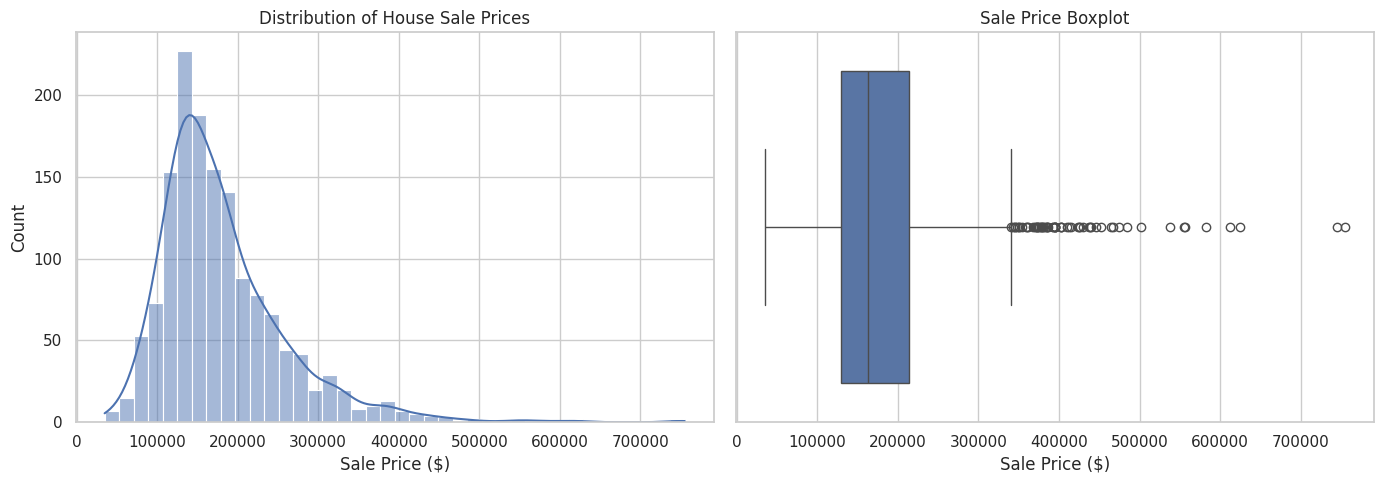

SALE PRICE OUTLIER DIAGNOSTICS
Q1: $129,975.00
Q3: $214,000.00
IQR: $84,025.00
Lower bound: $3,937.50
Upper bound: $340,037.50
Potential outliers: 61
Percentage of training data: 4.18%

Highest-priced properties:


,Id,OverallQual,GrLivArea,GarageArea,SalePrice
691,692,10,4316,832,755000
1182,1183,10,4476,813,745000
1169,1170,10,3627,807,625000
898,899,9,2364,820,611657
803,804,9,2822,1020,582933
1046,1047,9,2868,716,556581
440,441,10,2402,672,555000
769,770,8,3279,841,538000
178,179,9,2234,1166,501837
798,799,9,3140,820,485000


In [5]:

# CELL 5: Sale price distribution and outlier analysis

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Sale price distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    train_df["SalePrice"],
    bins=40,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of House Sale Prices")
axes[0].set_xlabel("Sale Price ($)")

sns.boxplot(
    x=train_df["SalePrice"],
    ax=axes[1]
)
axes[1].set_title("Sale Price Boxplot")
axes[1].set_xlabel("Sale Price ($)")

plt.tight_layout()
plt.show()

# 2. IQR-based outlier diagnostics
Q1 = train_df["SalePrice"].quantile(0.25)
Q3 = train_df["SalePrice"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

price_outliers = train_df[
    (train_df["SalePrice"] < lower_bound) |
    (train_df["SalePrice"] > upper_bound)
]

print("=" * 60)
print("SALE PRICE OUTLIER DIAGNOSTICS")
print("=" * 60)
print(f"Q1: ${Q1:,.2f}")
print(f"Q3: ${Q3:,.2f}")
print(f"IQR: ${IQR:,.2f}")
print(f"Lower bound: ${lower_bound:,.2f}")
print(f"Upper bound: ${upper_bound:,.2f}")
print(f"Potential outliers: {len(price_outliers)}")
print(
    f"Percentage of training data: "
    f"{len(price_outliers) / len(train_df) * 100:.2f}%"
)

print("\nHighest-priced properties:")
display(
    train_df.nlargest(10, "SalePrice")[
        ["Id", "OverallQual", "GrLivArea", "GarageArea", "SalePrice"]
    ]
)


TOP 15 NUMERICAL FEATURES CORRELATED WITH SALE PRICE


,Correlation with SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


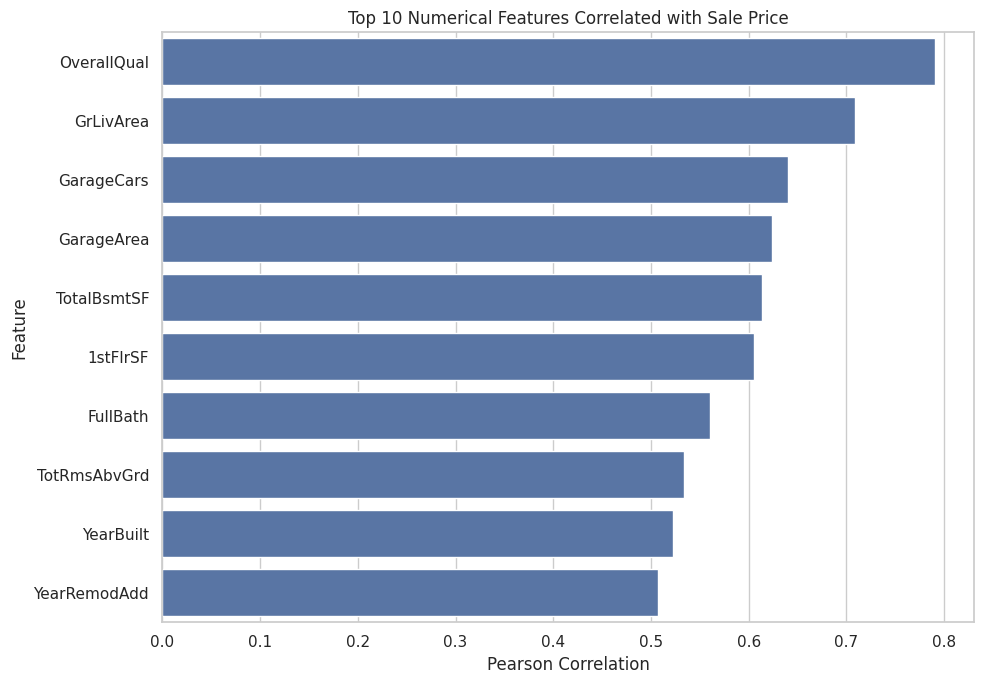

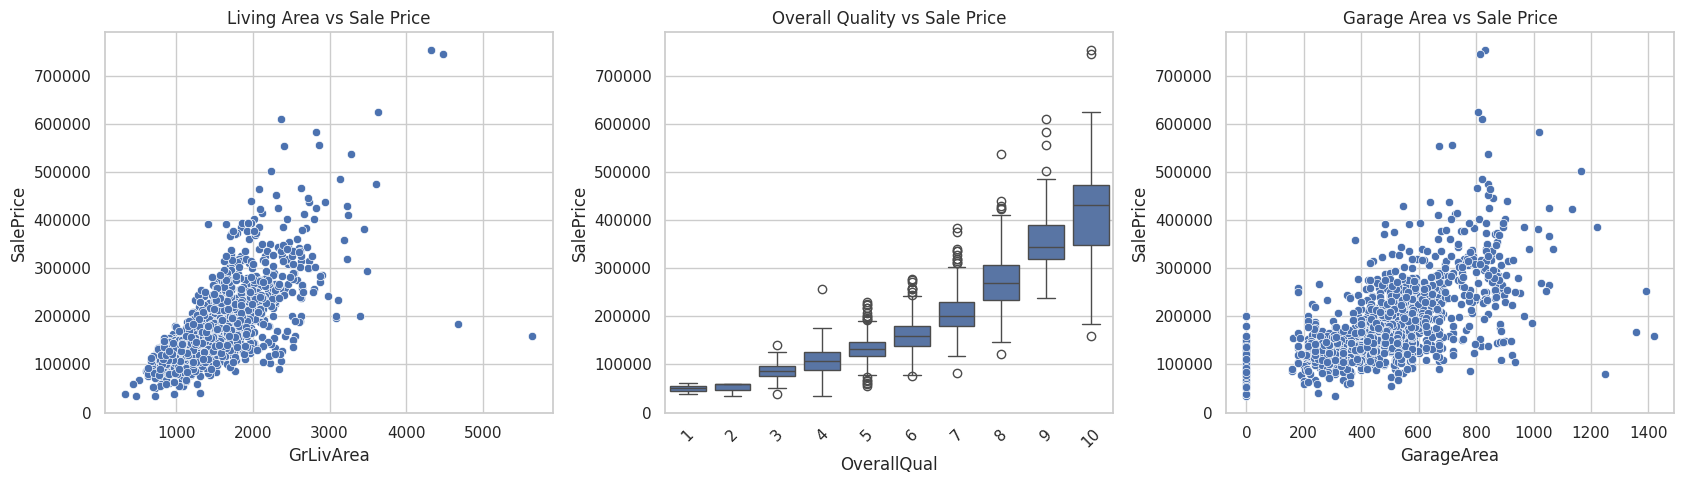

In [6]:

# CELL 6: Explore feature relationships with SalePrice

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Correlation of numerical features with SalePrice
numeric_df = train_df.select_dtypes(include=np.number)

correlations = (
    numeric_df.corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

print("=" * 65)
print("TOP 15 NUMERICAL FEATURES CORRELATED WITH SALE PRICE")
print("=" * 65)

display(correlations.head(15).to_frame("Correlation with SalePrice"))

# 2. Visualize the strongest correlations
top_features = correlations.head(10).index.tolist()

plt.figure(figsize=(10, 7))
sns.barplot(
    x=correlations.loc[top_features].values,
    y=top_features
)
plt.title("Top 10 Numerical Features Correlated with Sale Price")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# 3. Examine important property relationships
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.scatterplot(
    data=train_df,
    x="GrLivArea",
    y="SalePrice",
    ax=axes[0]
)
axes[0].set_title("Living Area vs Sale Price")

sns.boxplot(
    data=train_df,
    x="OverallQual",
    y="SalePrice",
    ax=axes[1]
)
axes[1].set_title("Overall Quality vs Sale Price")
axes[1].tick_params(axis="x", rotation=45)

sns.scatterplot(
    data=train_df,
    x="GarageArea",
    y="SalePrice",
    ax=axes[2]
)
axes[2].set_title("Garage Area vs Sale Price")

plt.tight_layout()
plt.show()


Missing-value summary:


,Missing_Count,Missing_Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


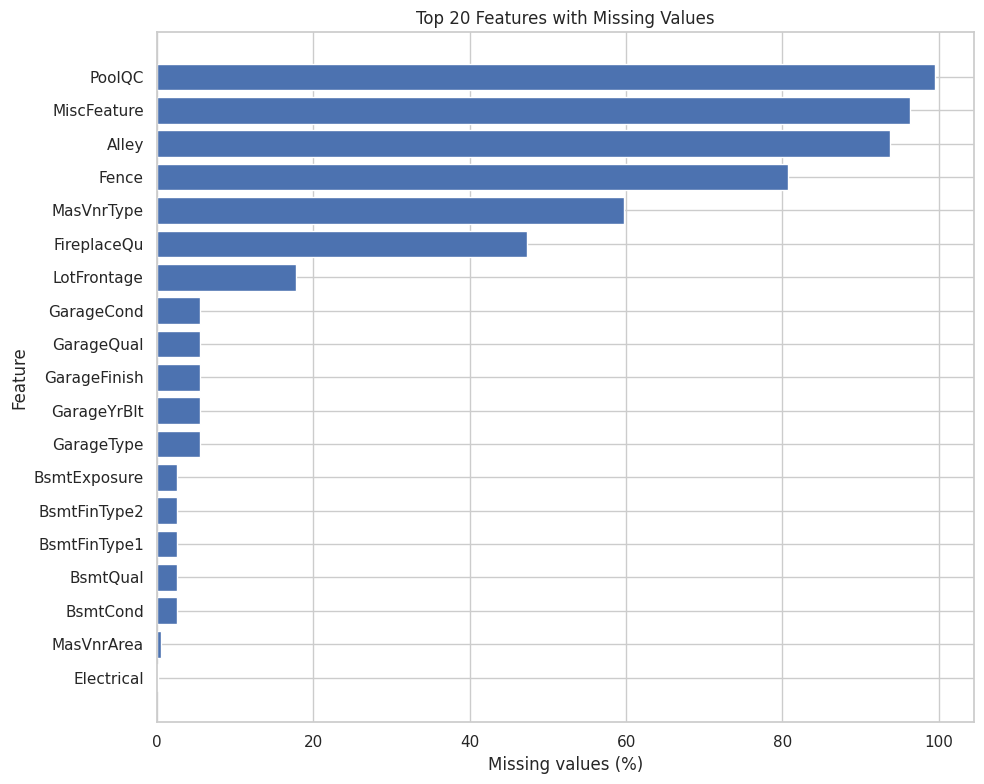


Missing SalePrice values: 0

Features with the most missing values across datasets:


,Train_Missing,Test_Missing,Train_Percent,Test_Percent
PoolQC,1453,1456.0,99.52,99.79
MiscFeature,1406,1408.0,96.30,96.50
Alley,1369,1352.0,93.77,92.67
Fence,1179,1169.0,80.75,80.12
MasVnrType,872,894.0,59.73,61.27
FireplaceQu,690,730.0,47.26,50.03
LotFrontage,259,227.0,17.74,15.56
GarageYrBlt,81,78.0,5.55,5.35
GarageFinish,81,78.0,5.55,5.35
GarageQual,81,78.0,5.55,5.35


In [7]:

# CELL 7: Missing-value analysis and visualization

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Missing-value counts for training data
missing_counts = train_df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(
    ascending=False
)

missing_summary = pd.DataFrame({
    "Missing_Count": missing_counts,
    "Missing_Percentage": (
        missing_counts / len(train_df) * 100
    ).round(2)
})

print("Missing-value summary:")
display(missing_summary)

# Plot the 20 columns with the most missing values
top_missing = missing_summary.head(20).sort_values(
    "Missing_Percentage", ascending=True
)

plt.figure(figsize=(10, 8))
plt.barh(
    top_missing.index,
    top_missing["Missing_Percentage"]
)
plt.xlabel("Missing values (%)")
plt.ylabel("Feature")
plt.title("Top 20 Features with Missing Values")
plt.tight_layout()
plt.show()

# Check missingness of the target
print("\nMissing SalePrice values:", train_df["SalePrice"].isnull().sum())

# Compare the number of missing values in both datasets
missing_comparison = pd.DataFrame({
    "Train_Missing": train_df.isnull().sum(),
    "Test_Missing": test_df.isnull().sum()
})

missing_comparison["Train_Percent"] = (
    missing_comparison["Train_Missing"] / len(train_df) * 100
).round(2)

missing_comparison["Test_Percent"] = (
    missing_comparison["Test_Missing"] / len(test_df) * 100
).round(2)

print("\nFeatures with the most missing values across datasets:")
display(
    missing_comparison.sort_values(
        "Train_Missing", ascending=False
    ).head(15)
)


In [8]:

# CELL 8: Inspect missing-value semantics and data consistency

# Work on copies; preserve the original datasets
train_work = train_df.copy()
test_work = test_df.copy()

# Features where missing values commonly mean the feature is absent
absence_categories = {
    "PoolQC": "No Pool",
    "MiscFeature": "None",
    "Alley": "No Alley Access",
    "Fence": "No Fence",
    "FireplaceQu": "No Fireplace",
    "GarageType": "No Garage",
    "GarageFinish": "No Garage",
    "GarageQual": "No Garage",
    "GarageCond": "No Garage",
    "BsmtQual": "No Basement",
    "BsmtCond": "No Basement",
    "BsmtExposure": "No Basement",
    "BsmtFinType1": "No Basement",
    "BsmtFinType2": "No Basement",
    "MasVnrType": "None"
}

print("=" * 70)
print("MISSING-VALUE SEMANTICS")
print("=" * 70)

for col, meaning in absence_categories.items():
    if col in train_work.columns:
        print(
            f"{col:15s} | Missing: "
            f"{train_work[col].isna().sum():4d} | "
            f"Likely meaning: {meaning}"
        )

print("\n" + "=" * 70)
print("NUMERICAL FEATURES WITH MISSING VALUES")
print("=" * 70)

numeric_missing = train_work.select_dtypes(include=np.number).isna().sum()
numeric_missing = numeric_missing[numeric_missing > 0]
print(numeric_missing.to_string())

print("\n" + "=" * 70)
print("TRAIN / TEST FEATURE CONSISTENCY")
print("=" * 70)

train_features = set(train_work.columns) - {"SalePrice"}
test_features = set(test_work.columns)

print("Features in train but not test:", sorted(train_features - test_features))
print("Features in test but not train:", sorted(test_features - train_features))
print("Training IDs unique:", train_work["Id"].is_unique)
print("Test IDs unique:", test_work["Id"].is_unique)
print("Training IDs overlap with test:",
      len(set(train_work["Id"]) & set(test_work["Id"])))

print("\nCleaning-plan inspection completed.")


MISSING-VALUE SEMANTICS
PoolQC          | Missing: 1453 | Likely meaning: No Pool
MiscFeature     | Missing: 1406 | Likely meaning: None
Alley           | Missing: 1369 | Likely meaning: No Alley Access
Fence           | Missing: 1179 | Likely meaning: No Fence
FireplaceQu     | Missing:  690 | Likely meaning: No Fireplace
GarageType      | Missing:   81 | Likely meaning: No Garage
GarageFinish    | Missing:   81 | Likely meaning: No Garage
GarageQual      | Missing:   81 | Likely meaning: No Garage
GarageCond      | Missing:   81 | Likely meaning: No Garage
BsmtQual        | Missing:   37 | Likely meaning: No Basement
BsmtCond        | Missing:   37 | Likely meaning: No Basement
BsmtExposure    | Missing:   38 | Likely meaning: No Basement
BsmtFinType1    | Missing:   37 | Likely meaning: No Basement
BsmtFinType2    | Missing:   38 | Likely meaning: No Basement
MasVnrType      | Missing:  872 | Likely meaning: None

NUMERICAL FEATURES WITH MISSING VALUES
LotFrontage    259
MasVnrArea 

In [9]:

# CELL 9: Semantic missing-value cleaning

# Start from the original datasets to keep this cell reproducible
train_clean = train_df.copy()
test_clean = test_df.copy()

# Categorical missing values that indicate feature absence
absence_labels = {
    "PoolQC": "No Pool",
    "MiscFeature": "None",
    "Alley": "No Alley Access",
    "Fence": "No Fence",
    "FireplaceQu": "No Fireplace",
    "GarageType": "No Garage",
    "GarageFinish": "No Garage",
    "GarageQual": "No Garage",
    "GarageCond": "No Garage",
    "BsmtQual": "No Basement",
    "BsmtCond": "No Basement",
    "BsmtExposure": "No Basement",
    "BsmtFinType1": "No Basement",
    "BsmtFinType2": "No Basement",
    "MasVnrType": "None"
}

for col, label in absence_labels.items():
    if col in train_clean.columns:
        train_clean[col] = train_clean[col].fillna(label)
        test_clean[col] = test_clean[col].fillna(label)

# Numerical missing values that indicate absence of a feature
zero_if_absent = [
    "MasVnrArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "BsmtFullBath",
    "BsmtHalfBath"
]

for col in zero_if_absent:
    if col in train_clean.columns:
        train_clean[col] = train_clean[col].fillna(0)
        test_clean[col] = test_clean[col].fillna(0)

# GarageYrBlt: keep missing values for now.
# The modeling pipeline will impute this feature without data leakage.

# LotFrontage: neighborhood median, then training median as fallback
frontage_medians = train_clean.groupby("Neighborhood")["LotFrontage"].median()
overall_frontage_median = train_clean["LotFrontage"].median()

for data in [train_clean, test_clean]:
    data["LotFrontage"] = data["LotFrontage"].fillna(
        data["Neighborhood"].map(frontage_medians)
    )
    data["LotFrontage"] = data["LotFrontage"].fillna(
        overall_frontage_median
    )

# Report remaining missing values before model-pipeline imputation
train_remaining = train_clean.isnull().sum()
test_remaining = test_clean.isnull().sum()

print("=" * 65)
print("MISSING VALUES AFTER SEMANTIC CLEANING")
print("=" * 65)

print("Training missing cells:", int(train_remaining.sum()))
print("Test missing cells:", int(test_remaining.sum()))

print("\nRemaining missing columns in training:")
print(train_remaining[train_remaining > 0].to_string())

print("\nRemaining missing columns in test:")
print(test_remaining[test_remaining > 0].to_string())

print("\nTraining shape:", train_clean.shape)
print("Test shape:", test_clean.shape)
print("\nSemantic missing-value cleaning completed.")


MISSING VALUES AFTER SEMANTIC CLEANING
Training missing cells: 82
Test missing cells: 90

Remaining missing columns in training:
Electrical      1
GarageYrBlt    81

Remaining missing columns in test:
MSZoning        4
Utilities       2
Exterior1st     1
Exterior2nd     1
KitchenQual     1
Functional      2
GarageYrBlt    78
SaleType        1

Training shape: (1460, 81)
Test shape: (1459, 80)

Semantic missing-value cleaning completed.


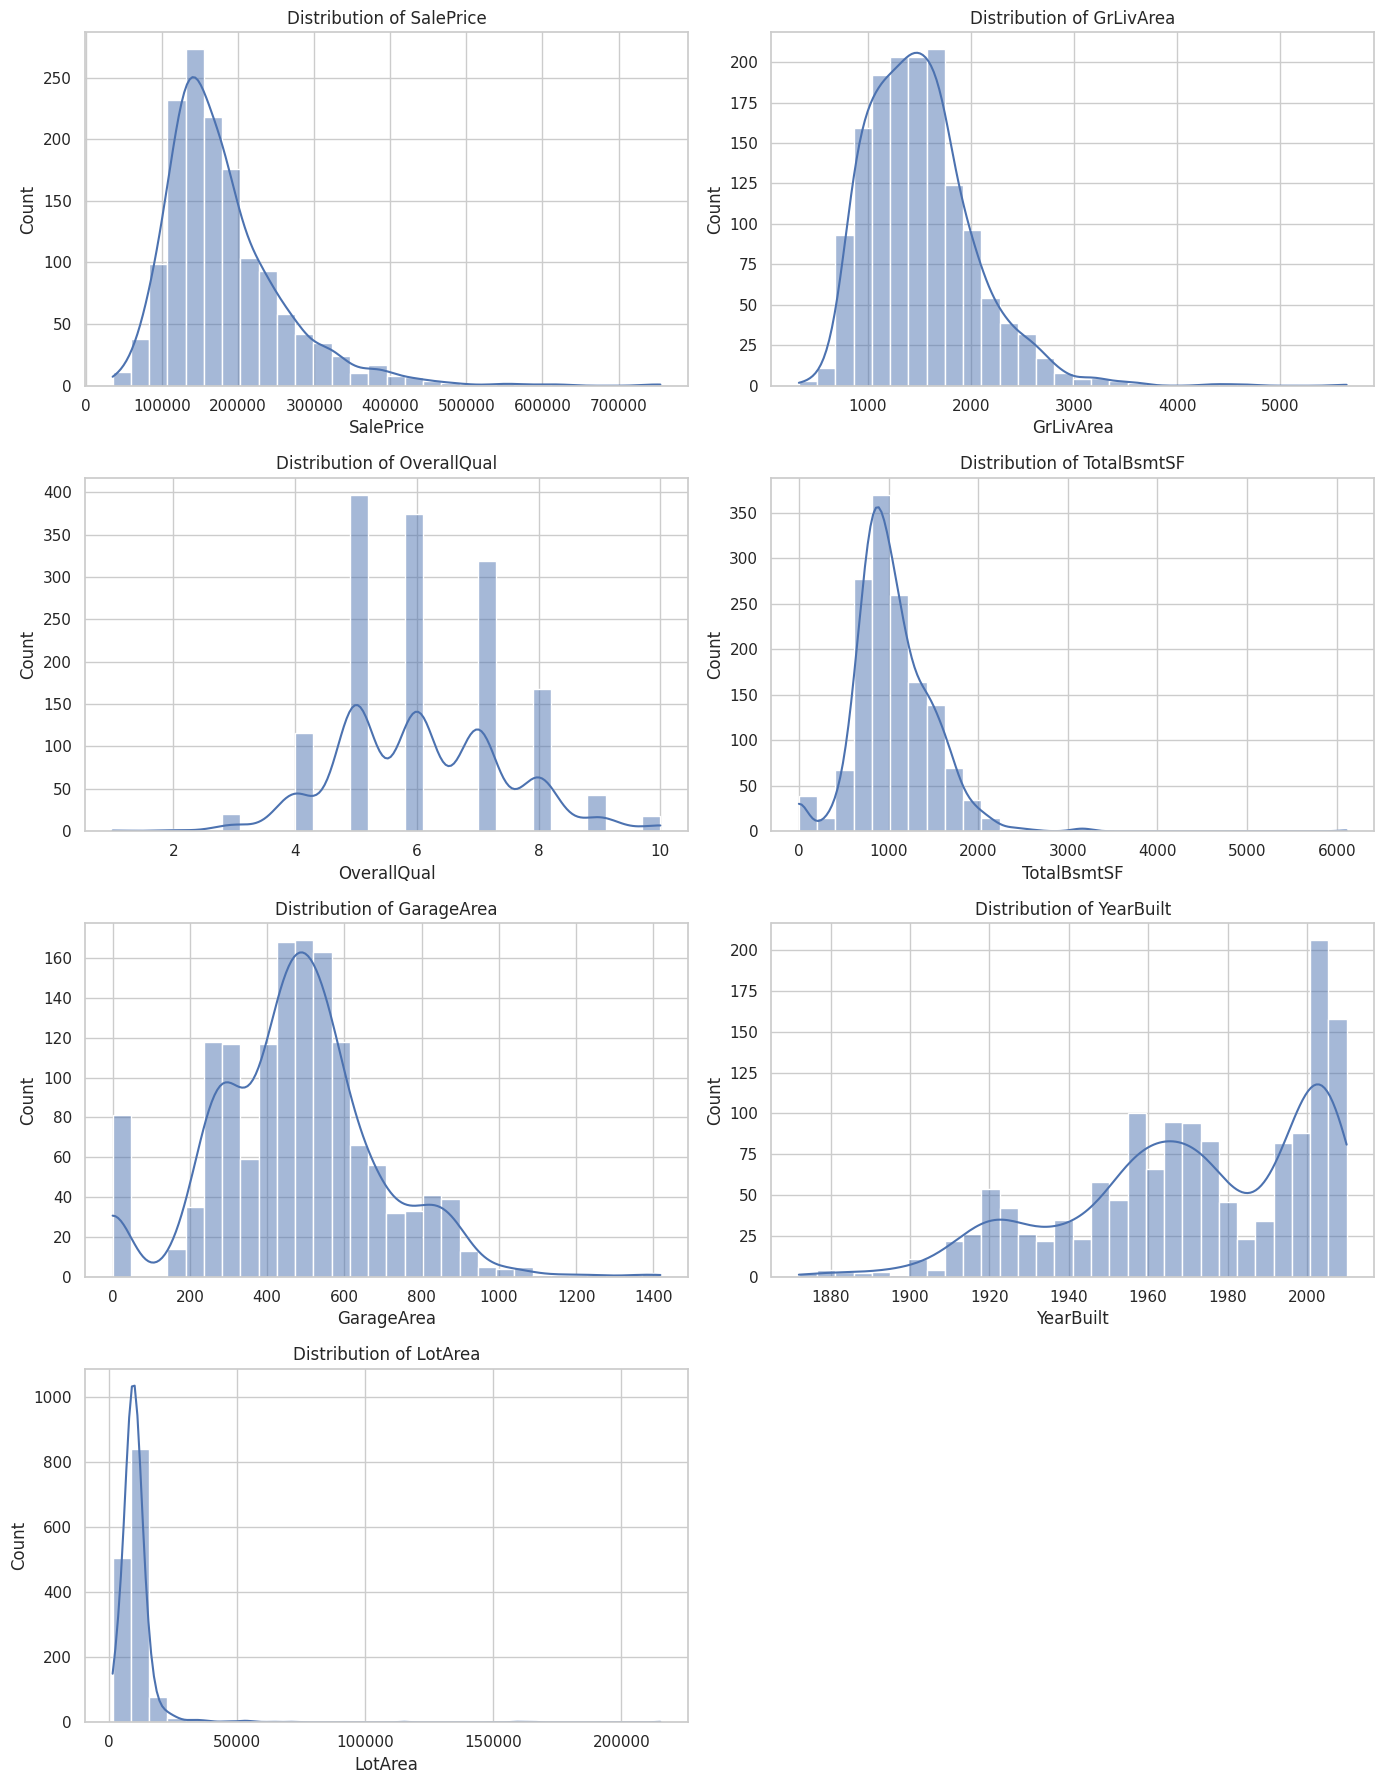

FEATURE SKEWNESS


,Skewness
LotArea,12.207688
SalePrice,1.882876
TotalBsmtSF,1.524255
GrLivArea,1.366560
OverallQual,0.216944
GarageArea,0.179981
YearBuilt,-0.613461



Interpretation:
Positive skewness indicates a longer right tail.
We will consider transformations only where they help model performance.


In [10]:

# CELL 10: Explore important numerical feature distributions

import matplotlib.pyplot as plt
import seaborn as sns

features_to_plot = [
    "SalePrice",
    "GrLivArea",
    "OverallQual",
    "TotalBsmtSF",
    "GarageArea",
    "YearBuilt",
    "LotArea"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    sns.histplot(
        data=train_clean,
        x=col,
        kde=True,
        ax=axes[i],
        bins=30
    )
    axes[i].set_title(f"Distribution of {col}")

# Hide unused subplot
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

# Skewness analysis
skewness = train_clean[features_to_plot].skew().sort_values(
    ascending=False
)

print("=" * 60)
print("FEATURE SKEWNESS")
print("=" * 60)
display(skewness.to_frame("Skewness"))

print("\nInterpretation:")
print("Positive skewness indicates a longer right tail.")
print("We will consider transformations only where they help model performance.")


In [11]:

# CELL 11: Create training and validation splits

from sklearn.model_selection import train_test_split

# Separate target and features
target = "SalePrice"

# Exclude target and identifier from model inputs
X = train_clean.drop(columns=["SalePrice", "Id"])
y = train_clean["SalePrice"]

# Keep test IDs separately for future prediction output
test_ids = test_clean["Id"].copy()
X_test = test_clean.drop(columns=["Id"])

# Reproducible 80/20 split
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("=" * 65)
print("TRAINING / VALIDATION SPLIT")
print("=" * 65)

print("Full training features:", X.shape)
print("Training split:", X_train.shape)
print("Validation split:", X_valid.shape)
print("Competition test features:", X_test.shape)

print("\nTarget statistics:")
print(f"Training mean SalePrice: ${y_train.mean():,.2f}")
print(f"Validation mean SalePrice: ${y_valid.mean():,.2f}")

print("\nTarget missing values:")
print("Training:", y_train.isna().sum())
print("Validation:", y_valid.isna().sum())

print("\nFeature columns match test:",
      set(X_train.columns) == set(X_test.columns))

print("\nData split completed successfully.")


TRAINING / VALIDATION SPLIT
Full training features: (1460, 79)
Training split: (1168, 79)
Validation split: (292, 79)
Competition test features: (1459, 79)

Target statistics:
Training mean SalePrice: $181,441.54
Validation mean SalePrice: $178,839.81

Target missing values:
Training: 0
Validation: 0

Feature columns match test: True

Data split completed successfully.


In [12]:

# CELL 12: Build leakage-safe preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns from training features
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing branches
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("=" * 65)
print("PREPROCESSING PIPELINE CONFIGURATION")
print("=" * 65)

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total input features:", len(numeric_features) + len(categorical_features))

print("\nNumerical pipeline:")
print(numeric_transformer)

print("\nCategorical pipeline:")
print(categorical_transformer)

print("\nPreprocessing pipeline configured successfully.")


PREPROCESSING PIPELINE CONFIGURATION
Numerical features: 36
Categorical features: 43
Total input features: 79

Numerical pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

Categorical pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))])

Preprocessing pipeline configured successfully.


In [13]:

# CELL 13: Train and compare regression models

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import pandas as pd
import numpy as np
import time

models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=10.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
        loss="squared_error"
    )
}

results = []
fitted_models = {}
validation_predictions = {}

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")
    start_time = time.time()

    # Fresh preprocessing pipeline for each model
    model_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("regressor", model)
    ])

    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_valid)

    mae = mean_absolute_error(y_valid, predictions)
    rmse = np.sqrt(mean_squared_error(y_valid, predictions))
    r2 = r2_score(y_valid, predictions)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training_Time_Seconds": round(time.time() - start_time, 2)
    })

    fitted_models[model_name] = model_pipeline
    validation_predictions[model_name] = predictions

    print(
        f"MAE: ${mae:,.2f} | "
        f"RMSE: ${rmse:,.2f} | "
        f"R²: {r2:.4f}"
    )

results_df = pd.DataFrame(results).sort_values("RMSE")

print("\n" + "=" * 75)
print("REGRESSION MODEL COMPARISON")
print("=" * 75)
display(results_df.round(4))

print("\nModel training and evaluation completed.")



Training Linear Regression...
MAE: $21,120.31 | RMSE: $65,355.61 | R²: 0.4431

Training Ridge Regression...
MAE: $19,153.20 | RMSE: $30,523.59 | R²: 0.8785

Training Random Forest...
MAE: $17,480.74 | RMSE: $28,893.65 | R²: 0.8912

Training Gradient Boosting...
MAE: $16,765.73 | RMSE: $26,434.66 | R²: 0.9089

REGRESSION MODEL COMPARISON


,Model,MAE,RMSE,R2,Training_Time_Seconds
3,Gradient Boosting,16765.7333,26434.6639,0.9089,2.35
2,Random Forest,17480.7355,28893.6471,0.8912,23.54
1,Ridge Regression,19153.1984,30523.5882,0.8785,0.17
0,Linear Regression,21120.3109,65355.6139,0.4431,0.70



Model training and evaluation completed.


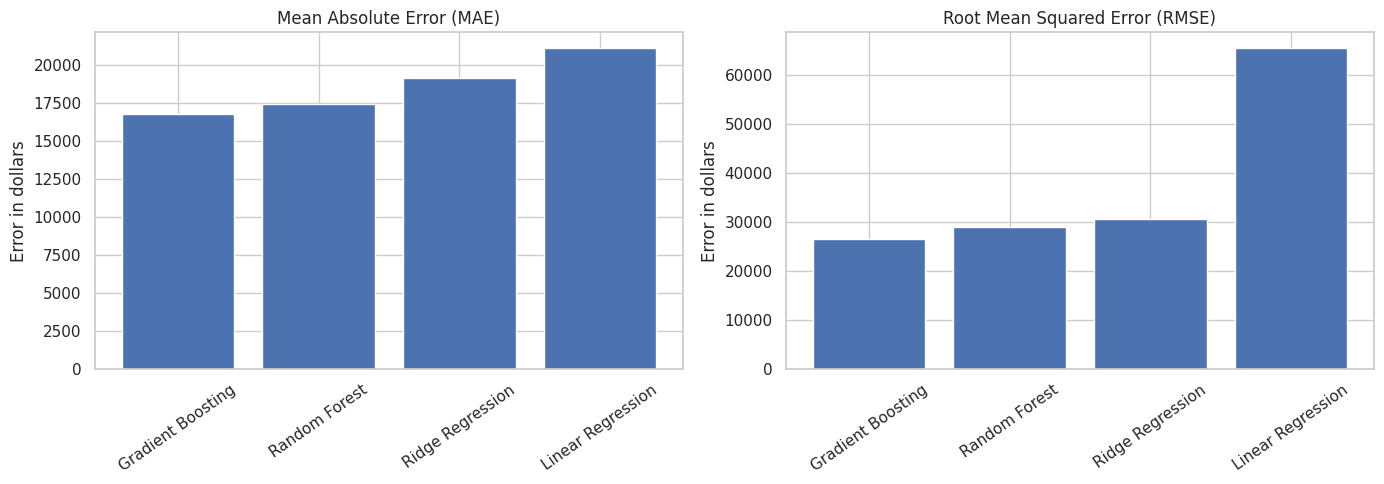

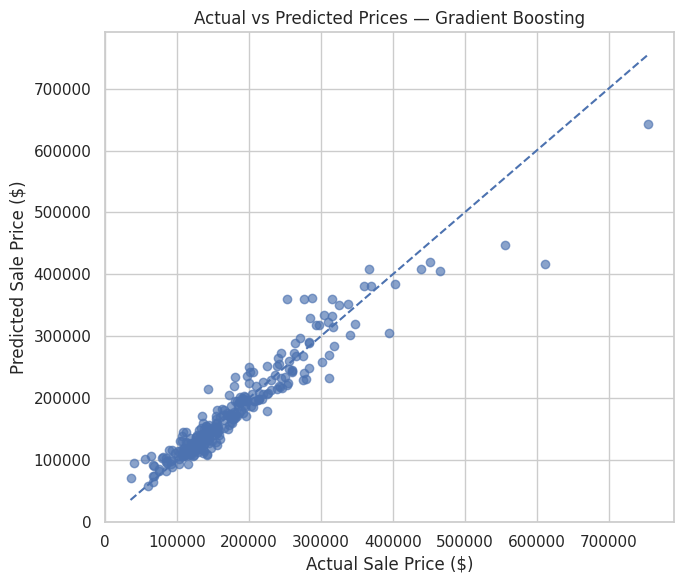

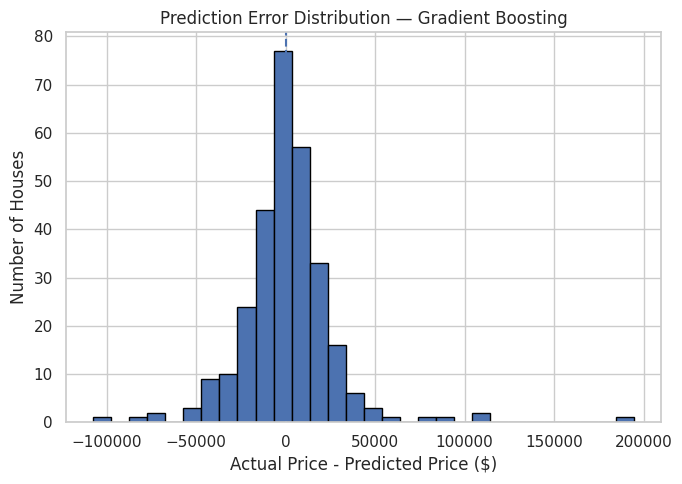

Best model: Gradient Boosting
Validation MAE: $16,765.73
Validation RMSE: $26,434.66


In [14]:

import matplotlib.pyplot as plt
import numpy as np

# 1. Compare MAE and RMSE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(results_df["Model"], results_df["MAE"])
axes[0].set_title("Mean Absolute Error (MAE)")
axes[0].set_ylabel("Error in dollars")
axes[0].tick_params(axis="x", rotation=35)

axes[1].bar(results_df["Model"], results_df["RMSE"])
axes[1].set_title("Root Mean Squared Error (RMSE)")
axes[1].set_ylabel("Error in dollars")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

# 2. Actual vs predicted prices for the best model
best_model_name = results_df.iloc[0]["Model"]
best_predictions = validation_predictions[best_model_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_valid, best_predictions, alpha=0.65)

min_price = min(y_valid.min(), best_predictions.min())
max_price = max(y_valid.max(), best_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.title(f"Actual vs Predicted Prices — {best_model_name}")
plt.tight_layout()
plt.show()

# 3. Prediction error distribution
residuals = y_valid.to_numpy() - best_predictions

plt.figure(figsize=(7, 5))
plt.hist(residuals, bins=30, edgecolor="black")
plt.axvline(0, linestyle="--")
plt.xlabel("Actual Price - Predicted Price ($)")
plt.ylabel("Number of Houses")
plt.title(f"Prediction Error Distribution — {best_model_name}")
plt.tight_layout()
plt.show()

print("Best model:", best_model_name)
print("Validation MAE: ${:,.2f}".format(
    np.mean(np.abs(residuals))
))
print("Validation RMSE: ${:,.2f}".format(
    np.sqrt(np.mean(residuals ** 2))
))


Largest prediction errors:


,Actual_Price,Predicted_Price,Error,Absolute_Error,Percentage_Error
74,611657,416828.27,194828.73,194828.73,31.85
139,755000,643272.20,111727.80,111727.80,14.80
168,556581,447810.84,108770.16,108770.16,19.54
43,253293,360770.09,-107477.09,107477.09,42.43
260,395000,305777.34,89222.66,89222.66,22.59
167,276000,359649.78,-83649.78,83649.78,30.31
6,311500,233003.72,78496.28,78496.28,25.20
53,287000,361235.41,-74235.41,74235.41,25.87
278,143000,215363.94,-72363.94,72363.94,50.60
270,465000,405117.45,59882.55,59882.55,12.88



Error summary:


,Error,Absolute_Error,Percentage_Error
count,292.00,292.00,292.00
mean,431.38,16765.73,9.98
std,26476.52,20472.84,13.30
min,-107477.09,49.45,0.03
25%,-10628.51,4673.70,3.10
50%,630.80,11052.25,6.95
75%,11187.55,21397.45,12.02
max,194828.73,194828.73,135.76


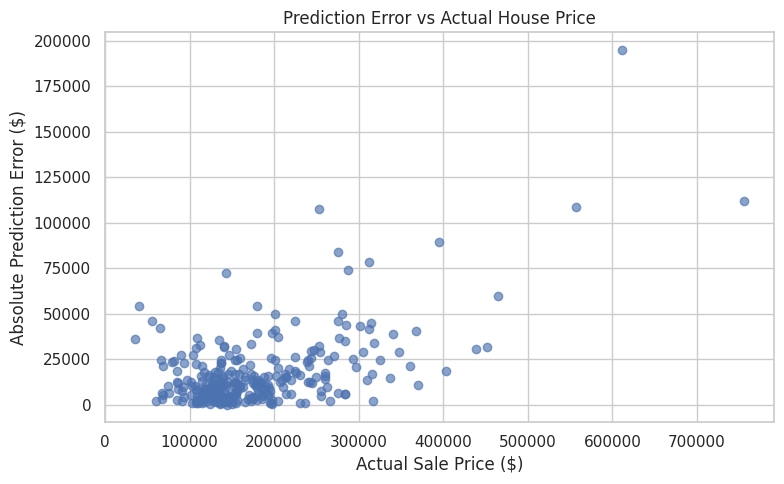

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create a validation analysis table
validation_analysis = pd.DataFrame({
    "Actual_Price": y_valid.to_numpy(),
    "Predicted_Price": best_predictions
})

validation_analysis["Error"] = (
    validation_analysis["Actual_Price"]
    - validation_analysis["Predicted_Price"]
)

validation_analysis["Absolute_Error"] = (
    validation_analysis["Error"].abs()
)

validation_analysis["Percentage_Error"] = (
    validation_analysis["Absolute_Error"]
    / validation_analysis["Actual_Price"]
) * 100

print("Largest prediction errors:")
display(
    validation_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .round(2)
)

print("\nError summary:")
display(
    validation_analysis[
        ["Error", "Absolute_Error", "Percentage_Error"]
    ].describe().round(2)
)

# Compare actual prices with absolute prediction errors
plt.figure(figsize=(8, 5))
plt.scatter(
    validation_analysis["Actual_Price"],
    validation_analysis["Absolute_Error"],
    alpha=0.65
)
plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Absolute Prediction Error ($)")
plt.title("Prediction Error vs Actual House Price")
plt.tight_layout()
plt.show()


In [16]:

# Find the original rows corresponding to the largest errors.
# validation_analysis retains the original validation-set indices.

top_error_indices = (
    validation_analysis
    .nlargest(10, "Absolute_Error")
    .index
)

# Retrieve property characteristics from the cleaned dataset.
error_properties = train_clean.loc[
    top_error_indices
].copy()

error_properties["PredictedPrice"] = (
    validation_analysis.loc[
        top_error_indices, "Predicted_Price"
    ]
)

error_properties["AbsoluteError"] = (
    validation_analysis.loc[
        top_error_indices, "Absolute_Error"
    ]
)

columns_to_inspect = [
    "Id", "SalePrice", "PredictedPrice", "AbsoluteError",
    "OverallQual", "OverallCond", "GrLivArea",
    "TotalBsmtSF", "1stFlrSF", "2ndFlrSF",
    "YearBuilt", "YearRemodAdd", "GarageCars",
    "GarageArea", "Neighborhood", "HouseStyle",
    "ExterQual", "KitchenQual"
]

columns_to_inspect = [
    col for col in columns_to_inspect
    if col in error_properties.columns
]

display(
    error_properties[columns_to_inspect]
    .sort_values("AbsoluteError", ascending=False)
    .round(2)
    .reset_index(drop=True)
)


,Id,SalePrice,PredictedPrice,AbsoluteError,OverallQual,OverallCond,GrLivArea,TotalBsmtSF,1stFlrSF,2ndFlrSF,YearBuilt,YearRemodAdd,GarageCars,GarageArea,Neighborhood,HouseStyle,ExterQual,KitchenQual
0,75,107400,416828.27,194828.73,3,6,1605,840,840,765,1915,1950,1,379,OldTown,2Story,Gd,TA
1,140,231500,643272.20,111727.80,6,5,1764,928,928,836,1997,1997,2,470,CollgCr,2Story,TA,Gd
2,169,183500,447810.84,108770.16,7,5,1720,840,840,880,2004,2004,2,440,Gilbert,2Story,Gd,Gd
3,44,130250,360770.09,107477.09,5,6,938,938,938,0,1975,1980,1,308,CollgCr,1Story,TA,TA
4,261,176000,305777.34,89222.66,6,5,1382,1362,1382,0,1962,1962,2,884,NAmes,SLvl,TA,TA
5,168,325624,359649.78,83649.78,8,5,2161,1582,1610,551,2007,2007,3,789,NridgHt,2Story,Gd,Ex
6,7,307000,233003.72,78496.28,8,5,1694,1686,1694,0,2004,2005,2,636,Somerst,1Story,Gd,Gd
7,54,385000,361235.41,74235.41,9,5,1842,1842,1842,0,1981,1987,3,894,Veenker,1Story,Gd,Gd
8,279,415298,215363.94,72363.94,9,5,2121,2121,2121,0,2006,2007,3,732,NridgHt,1Story,Ex,Ex
9,271,266000,405117.45,59882.55,8,5,1939,1095,1095,844,2006,2006,3,1053,Somerst,2Story,Gd,Gd


In [17]:

# Verify the four largest-error properties using their original IDs.
extreme_ids = [75, 140, 169, 44]

selected_columns = [
    "Id", "SalePrice", "OverallQual", "OverallCond",
    "GrLivArea", "TotalBsmtSF", "YearBuilt",
    "YearRemodAdd", "Neighborhood", "HouseStyle",
    "ExterQual", "KitchenQual", "LotArea",
    "FullBath", "BedroomAbvGr", "GarageCars"
]

selected_columns = [
    col for col in selected_columns
    if col in train_clean.columns
]

print("Original training records:")
display(
    train_clean.loc[
        train_clean["Id"].isin(extreme_ids),
        selected_columns
    ].sort_values("Id")
)

print("\nValidation residuals for these records:")
display(
    validation_analysis.loc[
        validation_analysis.index.isin(top_error_indices)
    ].sort_values("Absolute_Error", ascending=False).head(10).round(2)
)


Original training records:


,Id,SalePrice,OverallQual,OverallCond,GrLivArea,TotalBsmtSF,YearBuilt,YearRemodAdd,Neighborhood,HouseStyle,ExterQual,KitchenQual,LotArea,FullBath,BedroomAbvGr,GarageCars
43,44,130250,5,6,938,938,1975,1980,CollgCr,1Story,TA,TA,9200,1,3,1
74,75,107400,3,6,1605,840,1915,1950,OldTown,2Story,Gd,TA,5790,2,3,1
139,140,231500,6,5,1764,928,1997,1997,CollgCr,2Story,TA,Gd,15426,2,3,2
168,169,183500,7,5,1720,840,2004,2004,Gilbert,2Story,Gd,Gd,8244,2,3,2



Validation residuals for these records:


,Actual_Price,Predicted_Price,Error,Absolute_Error,Percentage_Error
74,611657,416828.27,194828.73,194828.73,31.85
139,755000,643272.20,111727.80,111727.80,14.80
168,556581,447810.84,108770.16,108770.16,19.54
43,253293,360770.09,-107477.09,107477.09,42.43
260,395000,305777.34,89222.66,89222.66,22.59
167,276000,359649.78,-83649.78,83649.78,30.31
6,311500,233003.72,78496.28,78496.28,25.20
53,287000,361235.41,-74235.41,74235.41,25.87
278,143000,215363.94,-72363.94,72363.94,50.60
270,465000,405117.45,59882.55,59882.55,12.88


In [18]:

# Map validation predictions to their original training rows.
validation_results = pd.DataFrame({
    "Original_Index": X_valid.index,
    "Actual_Price": y_valid.to_numpy(),
    "Predicted_Price": best_predictions
})

validation_results["Error"] = (
    validation_results["Actual_Price"]
    - validation_results["Predicted_Price"]
)

validation_results["Absolute_Error"] = (
    validation_results["Error"].abs()
)

# Attach the original property IDs.
validation_results["Id"] = (
    train_clean.loc[
        validation_results["Original_Index"], "Id"
    ].to_numpy()
)

# Show the ten largest errors with the correct IDs.
largest_errors = validation_results.nlargest(
    10, "Absolute_Error"
)

display(
    largest_errors[
        [
            "Original_Index", "Id", "Actual_Price",
            "Predicted_Price", "Error", "Absolute_Error"
        ]
    ].round(2).reset_index(drop=True)
)

print("Validation rows:", len(validation_results))
print("Unique property IDs:", validation_results["Id"].nunique())


,Original_Index,Id,Actual_Price,Predicted_Price,Error,Absolute_Error
0,898,899,611657,416828.27,194828.73,194828.73
1,691,692,755000,643272.20,111727.80,111727.80
2,1046,1047,556581,447810.84,108770.16,108770.16
3,581,582,253293,360770.09,-107477.09,107477.09
4,774,775,395000,305777.34,89222.66,89222.66
5,261,262,276000,359649.78,-83649.78,83649.78
6,218,219,311500,233003.72,78496.28,78496.28
7,1024,1025,287000,361235.41,-74235.41,74235.41
8,588,589,143000,215363.94,-72363.94,72363.94
9,1243,1244,465000,405117.45,59882.55,59882.55


Validation rows: 292
Unique property IDs: 292


In [19]:

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

xgb_model = XGBRegressor(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.05,
    reg_lambda=2.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("regressor", xgb_model)
])

print("Training XGBoost...")
start_time = time.time()

xgb_pipeline.fit(X_train, y_train)
xgb_predictions = xgb_pipeline.predict(X_valid)

xgb_mae = mean_absolute_error(y_valid, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_valid, xgb_predictions))
xgb_r2 = r2_score(y_valid, xgb_predictions)

print("\nXGBoost validation results")
print(f"MAE:  ${xgb_mae:,.2f}")
print(f"RMSE: ${xgb_rmse:,.2f}")
print(f"R²:    {xgb_r2:.4f}")
print(f"Training time: {time.time() - start_time:.2f} seconds")


Training XGBoost...

XGBoost validation results
MAE:  $15,337.26
RMSE: $24,631.85
R²:    0.9209
Training time: 4.96 seconds


In [20]:

# Add XGBoost to the existing comparison table
xgb_result = pd.DataFrame([{
    "Model": "XGBoost",
    "MAE": xgb_mae,
    "RMSE": xgb_rmse,
    "R2": xgb_r2,
    "Training_Time_Seconds": 4.96
}])

all_results_df = pd.concat(
    [results_df, xgb_result],
    ignore_index=True
).sort_values("RMSE").reset_index(drop=True)

print("UPDATED MODEL COMPARISON")
display(all_results_df.round(4))

# Keep the best model's predictions and name available
best_model_name = all_results_df.iloc[0]["Model"]

if best_model_name == "XGBoost":
    best_predictions = xgb_predictions
    best_pipeline = xgb_pipeline
else:
    best_predictions = validation_predictions[best_model_name]
    best_pipeline = fitted_models[best_model_name]

print("\nCurrent best model:", best_model_name)


UPDATED MODEL COMPARISON


,Model,MAE,RMSE,R2,Training_Time_Seconds
0,XGBoost,15337.2637,24631.8519,0.9209,4.96
1,Gradient Boosting,16765.7333,26434.6639,0.9089,2.35
2,Random Forest,17480.7355,28893.6471,0.8912,23.54
3,Ridge Regression,19153.1984,30523.5882,0.8785,0.17
4,Linear Regression,21120.3109,65355.6139,0.4431,0.70



Current best model: XGBoost


In [21]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import numpy as np
import time

# Transform the target; all SalePrice values are positive.
y_train_log = np.log1p(y_train)

xgb_log_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("regressor", XGBRegressor(
        n_estimators=800,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.05,
        reg_lambda=2.0,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

print("Training XGBoost with log-transformed target...")
start_time = time.time()

xgb_log_pipeline.fit(X_train, y_train_log)

# Convert predictions back to dollar prices.
log_predictions = xgb_log_pipeline.predict(X_valid)
xgb_log_predictions = np.maximum(np.expm1(log_predictions), 0)

log_mae = mean_absolute_error(y_valid, xgb_log_predictions)
log_rmse = np.sqrt(mean_squared_error(y_valid, xgb_log_predictions))
log_r2 = r2_score(y_valid, xgb_log_predictions)

print("\nLog-target XGBoost validation results")
print(f"MAE:  ${log_mae:,.2f}")
print(f"RMSE: ${log_rmse:,.2f}")
print(f"R²:    {log_r2:.4f}")
print(f"Training time: {time.time() - start_time:.2f} seconds")

print("\nCurrent XGBoost baseline")
print(f"MAE:  ${xgb_mae:,.2f}")
print(f"RMSE: ${xgb_rmse:,.2f}")
print(f"R²:    {xgb_r2:.4f}")


Training XGBoost with log-transformed target...

Log-target XGBoost validation results
MAE:  $15,324.30
RMSE: $26,162.87
R²:    0.9108
Training time: 3.41 seconds

Current XGBoost baseline
MAE:  $15,337.26
RMSE: $24,631.85
R²:    0.9209


In [22]:

%pip install -q catboost lightgbm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.6 MB/s eta 0:00:00


In [23]:

from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import time

# Define both models
advanced_models = {
    "CatBoost": CatBoostRegressor(
        iterations=1000,
        learning_rate=0.03,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=0,
        allow_writing_files=False,
        thread_count=-1
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=-1,
        num_leaves=31,
        min_child_samples=20,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_alpha=0.05,
        reg_lambda=2.0,
        objective="regression",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )
}

# Store fitted models and validation predictions
advanced_fitted_models = {}
advanced_predictions = {}
advanced_results = []

for model_name, model in advanced_models.items():
    print(f"\nTraining {model_name}...")
    start_time = time.time()

    model_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("regressor", model)
    ])

    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_valid)

    mae = mean_absolute_error(y_valid, predictions)
    rmse = np.sqrt(mean_squared_error(y_valid, predictions))
    r2 = r2_score(y_valid, predictions)
    elapsed = round(time.time() - start_time, 2)

    advanced_fitted_models[model_name] = model_pipeline
    advanced_predictions[model_name] = predictions

    advanced_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training_Time_Seconds": elapsed
    })

    print(f"MAE:  ${mae:,.2f}")
    print(f"RMSE: ${rmse:,.2f}")
    print(f"R²:    {r2:.4f}")
    print(f"Training time: {elapsed:.2f} seconds")

# Add both models to the comparison table
advanced_results_df = pd.DataFrame(advanced_results)

all_results_df = pd.concat(
    [all_results_df, advanced_results_df],
    ignore_index=True
)

# Keep the best result for each model name if this cell is rerun
all_results_df = (
    all_results_df
    .sort_values("RMSE")
    .drop_duplicates(subset=["Model"], keep="last")
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("\n" + "=" * 80)
print("UPDATED MODEL COMPARISON — LOWER MAE/RMSE IS BETTER")
print("=" * 80)
display(all_results_df.round(4))

print("\nCurrent best model by validation RMSE:",
      all_results_df.iloc[0]["Model"])



Training CatBoost...
MAE:  $15,554.85
RMSE: $26,360.67
R²:    0.9094
Training time: 6.21 seconds

Training LightGBM...
MAE:  $16,536.92
RMSE: $27,752.43
R²:    0.8996
Training time: 2.54 seconds

UPDATED MODEL COMPARISON — LOWER MAE/RMSE IS BETTER


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Model,MAE,RMSE,R2,Training_Time_Seconds
0,XGBoost,15337.2637,24631.8519,0.9209,4.96
1,CatBoost,15554.8531,26360.6749,0.9094,6.21
2,Gradient Boosting,16765.7333,26434.6639,0.9089,2.35
3,LightGBM,16536.9166,27752.4346,0.8996,2.54
4,Random Forest,17480.7355,28893.6471,0.8912,23.54
5,Ridge Regression,19153.1984,30523.5882,0.8785,0.17
6,Linear Regression,21120.3109,65355.6139,0.4431,0.70



Current best model by validation RMSE: XGBoost


In [25]:

from sklearn.ensemble import HistGradientBoostingRegressor, AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy import sparse
import numpy as np
import pandas as pd
import time

more_models = {
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ),
    "AdaBoost": AdaBoostRegressor(
        estimator=DecisionTreeRegressor(
            max_depth=4,
            min_samples_leaf=5,
            random_state=42
        ),
        n_estimators=300,
        learning_rate=0.03,
        loss="linear",
        random_state=42
    )
}

more_fitted_models = {}
more_predictions = {}
more_results = []

for model_name, model in more_models.items():
    print(f"\nTraining {model_name}...")
    start_time = time.time()

    # HistGradientBoosting requires dense input.
    steps = [("preprocessor", clone(preprocessor))]

    if model_name == "HistGradientBoosting":
        steps.append((
            "to_dense",
            FunctionTransformer(
                lambda x: x.toarray() if sparse.issparse(x) else x,
                accept_sparse=True,
                feature_names_out="one-to-one"
            )
        ))

    steps.append(("regressor", model))
    model_pipeline = Pipeline(steps=steps)

    try:
        model_pipeline.fit(X_train, y_train)
        predictions = model_pipeline.predict(X_valid)

        mae = mean_absolute_error(y_valid, predictions)
        rmse = np.sqrt(mean_squared_error(y_valid, predictions))
        r2 = r2_score(y_valid, predictions)
        elapsed = round(time.time() - start_time, 2)

        more_fitted_models[model_name] = model_pipeline
        more_predictions[model_name] = predictions

        more_results.append({
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
            "Training_Time_Seconds": elapsed
        })

        print(f"MAE:  ${mae:,.2f}")
        print(f"RMSE: ${rmse:,.2f}")
        print(f"R²:    {r2:.4f}")
        print(f"Training time: {elapsed:.2f} seconds")

    except Exception as e:
        print(f"{model_name} failed: {type(e).__name__}: {e}")

# Update the leaderboard only with successful runs.
if more_results:
    more_results_df = pd.DataFrame(more_results)

    all_results_df = pd.concat(
        [all_results_df, more_results_df],
        ignore_index=True
    )

    all_results_df = (
        all_results_df
        .sort_values("RMSE")
        .drop_duplicates(subset=["Model"], keep="last")
        .sort_values("RMSE")
        .reset_index(drop=True)
    )

    print("\nUPDATED MODEL LEADERBOARD")
    display(all_results_df.round(4))

    print(
        "\nCurrent best model by validation RMSE:",
        all_results_df.iloc[0]["Model"]
    )
else:
    print("No new models completed successfully.")



Training HistGradientBoosting...
MAE:  $16,859.89
RMSE: $28,398.28
R²:    0.8949
Training time: 7.56 seconds

Training AdaBoost...
MAE:  $21,548.78
RMSE: $33,060.00
R²:    0.8575
Training time: 6.24 seconds

UPDATED MODEL LEADERBOARD


,Model,MAE,RMSE,R2,Training_Time_Seconds
0,XGBoost,15337.2637,24631.8519,0.9209,4.96
1,CatBoost,15554.8531,26360.6749,0.9094,6.21
2,Gradient Boosting,16765.7333,26434.6639,0.9089,2.35
3,LightGBM,16536.9166,27752.4346,0.8996,2.54
4,HistGradientBoosting,16859.8897,28398.2800,0.8949,7.56
5,Random Forest,17480.7355,28893.6471,0.8912,23.54
6,Ridge Regression,19153.1984,30523.5882,0.8785,0.17
7,AdaBoost,21548.7818,33059.9951,0.8575,6.24
8,Linear Regression,21120.3109,65355.6139,0.4431,0.70



Current best model by validation RMSE: XGBoost


In [26]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import time

print("Training ExtraTrees...")
start_time = time.time()

extra_trees_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("regressor", ExtraTreesRegressor(
        n_estimators=500,
        max_features=0.8,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

extra_trees_pipeline.fit(X_train, y_train)
extra_trees_predictions = extra_trees_pipeline.predict(X_valid)

extra_trees_mae = mean_absolute_error(
    y_valid, extra_trees_predictions
)
extra_trees_rmse = np.sqrt(mean_squared_error(
    y_valid, extra_trees_predictions
))
extra_trees_r2 = r2_score(y_valid, extra_trees_predictions)
extra_trees_time = round(time.time() - start_time, 2)

print(f"MAE:  ${extra_trees_mae:,.2f}")
print(f"RMSE: ${extra_trees_rmse:,.2f}")
print(f"R²:    {extra_trees_r2:.4f}")
print(f"Training time: {extra_trees_time:.2f} seconds")

# Save the model and predictions
extra_trees_pipeline  # fitted pipeline

more_fitted_models["ExtraTrees"] = extra_trees_pipeline
more_predictions["ExtraTrees"] = extra_trees_predictions

extra_trees_result = pd.DataFrame([{
    "Model": "ExtraTrees",
    "MAE": extra_trees_mae,
    "RMSE": extra_trees_rmse,
    "R2": extra_trees_r2,
    "Training_Time_Seconds": extra_trees_time
}])

all_results_df = pd.concat(
    [all_results_df, extra_trees_result],
    ignore_index=True
)

all_results_df = (
    all_results_df
    .sort_values("RMSE")
    .drop_duplicates(subset=["Model"], keep="last")
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("\nUPDATED MODEL LEADERBOARD")
display(all_results_df.round(4))


Training ExtraTrees...
MAE:  $17,663.62
RMSE: $28,814.99
R²:    0.8918
Training time: 40.63 seconds

UPDATED MODEL LEADERBOARD


,Model,MAE,RMSE,R2,Training_Time_Seconds
0,XGBoost,15337.2637,24631.8519,0.9209,4.96
1,CatBoost,15554.8531,26360.6749,0.9094,6.21
2,Gradient Boosting,16765.7333,26434.6639,0.9089,2.35
3,LightGBM,16536.9166,27752.4346,0.8996,2.54
4,HistGradientBoosting,16859.8897,28398.2800,0.8949,7.56
5,ExtraTrees,17663.6231,28814.9893,0.8918,40.63
6,Random Forest,17480.7355,28893.6471,0.8912,23.54
7,Ridge Regression,19153.1984,30523.5882,0.8785,0.17
8,AdaBoost,21548.7818,33059.9951,0.8575,6.24
9,Linear Regression,21120.3109,65355.6139,0.4431,0.70


In [27]:

from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
import numpy as np
import pandas as pd
import time

# Three-fold CV, with reproducible shuffling
cv = KFold(n_splits=3, shuffle=True, random_state=42)

# XGBoost pipeline
xgb_tuning_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    ))
])

xgb_param_distributions = {
    "regressor__n_estimators": [400, 600, 800, 1000],
    "regressor__learning_rate": [0.02, 0.03, 0.05],
    "regressor__max_depth": [2, 3, 4, 5],
    "regressor__min_child_weight": [1, 3, 5],
    "regressor__subsample": [0.7, 0.8, 0.9, 1.0],
    "regressor__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "regressor__reg_alpha": [0, 0.05, 0.2, 0.5],
    "regressor__reg_lambda": [1, 2, 5, 10]
}

# CatBoost pipeline
cat_tuning_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", CatBoostRegressor(
        loss_function="RMSE",
        random_seed=42,
        verbose=0,
        allow_writing_files=False,
        thread_count=1
    ))
])

cat_param_distributions = {
    "regressor__iterations": [400, 600, 800, 1000],
    "regressor__learning_rate": [0.02, 0.03, 0.05],
    "regressor__depth": [4, 5, 6, 7, 8],
    "regressor__l2_leaf_reg": [2, 3, 5, 7, 10],
    "regressor__random_strength": [0.1, 0.5, 1.0, 2.0]
}

# Run a randomized search for each model
tuning_searches = {}
tuned_pipelines = {}
tuning_results = []

search_configs = [
    ("XGBoost", xgb_tuning_pipeline, xgb_param_distributions),
    ("CatBoost", cat_tuning_pipeline, cat_param_distributions)
]

for model_name, pipeline, param_distributions in search_configs:
    print(f"\n{'=' * 65}")
    print(f"Tuning {model_name} — 12 combinations, 3-fold CV")
    print("=" * 65)

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions,
        n_iter=12,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        refit=True,
        error_score="raise"
    )

    start_time = time.time()
    search.fit(X_train, y_train)
    elapsed = round(time.time() - start_time, 2)

    tuning_searches[model_name] = search
    tuned_pipelines[model_name] = search.best_estimator_

    # Evaluate the tuned model on the untouched validation set
    valid_predictions = search.best_estimator_.predict(X_valid)

    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

    mae = mean_absolute_error(y_valid, valid_predictions)
    rmse = np.sqrt(mean_squared_error(y_valid, valid_predictions))
    r2 = r2_score(y_valid, valid_predictions)

    tuning_results.append({
        "Model": f"Tuned {model_name}",
        "CV_RMSE": -search.best_score_,
        "Validation_MAE": mae,
        "Validation_RMSE": rmse,
        "Validation_R2": r2,
        "Search_Time_Seconds": elapsed
    })

    print(f"\nBest CV RMSE: ${-search.best_score_:,.2f}")
    print(f"Validation MAE: ${mae:,.2f}")
    print(f"Validation RMSE: ${rmse:,.2f}")
    print(f"Validation R²: {r2:.4f}")
    print(f"Search time: {elapsed:.2f} seconds")
    print("Best parameters:")
    print(search.best_params_)

tuned_results_df = pd.DataFrame(tuning_results)

print("\nTUNED MODEL COMPARISON")
display(tuned_results_df.round(4))



Tuning XGBoost — 12 combinations, 3-fold CV
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best CV RMSE: $28,019.64
Validation MAE: $15,244.33
Validation RMSE: $24,216.42
Validation R²: 0.9235
Search time: 33.57 seconds
Best parameters:
{'regressor__subsample': 0.8, 'regressor__reg_lambda': 2, 'regressor__reg_alpha': 0.05, 'regressor__n_estimators': 800, 'regressor__min_child_weight': 1, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.02, 'regressor__colsample_bytree': 0.7}

Tuning CatBoost — 12 combinations, 3-fold CV
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best CV RMSE: $27,411.87
Validation MAE: $15,435.65
Validation RMSE: $25,870.20
Validation R²: 0.9127
Search time: 297.63 seconds
Best parameters:
{'regressor__random_strength': 1.0, 'regressor__learning_rate': 0.05, 'regressor__l2_leaf_reg': 7, 'regressor__iterations': 1000, 'regressor__depth': 5}

TUNED MODEL COMPARISON


,Model,CV_RMSE,Validation_MAE,Validation_RMSE,Validation_R2,Search_Time_Seconds
0,Tuned XGBoost,28019.6361,15244.3340,24216.4202,0.9235,33.57
1,Tuned CatBoost,27411.8705,15435.6513,25870.2004,0.9127,297.63


In [29]:

from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import time

# Clone the tuned pipelines to build the stacking model.
# Each base estimator includes its own preprocessing pipeline.
stack_estimators = [
    ("xgb", clone(tuned_pipelines["XGBoost"])),
    ("cat", clone(tuned_pipelines["CatBoost"]))
]

stack_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

stack_model = StackingRegressor(
    estimators=stack_estimators,
    final_estimator=Ridge(alpha=10.0),
    cv=stack_cv,
    passthrough=False,
    n_jobs=1
)

print("Training XGBoost + CatBoost stacking ensemble...")
start_time = time.time()

stack_model.fit(X_train, y_train)
stack_predictions = stack_model.predict(X_valid)

stack_time = round(time.time() - start_time, 2)

stack_mae = mean_absolute_error(y_valid, stack_predictions)
stack_rmse = np.sqrt(mean_squared_error(y_valid, stack_predictions))
stack_r2 = r2_score(y_valid, stack_predictions)

print("\nSTACKING ENSEMBLE RESULTS")
print(f"MAE:  ${stack_mae:,.2f}")
print(f"RMSE: ${stack_rmse:,.2f}")
print(f"R²:    {stack_r2:.4f}")
print(f"Training time: {stack_time:.2f} seconds")

# Save predictions and fitted model for later comparison.
stack_validation_predictions = stack_predictions
stack_fitted_model = stack_model

# Compare against the tuned individual models.
stack_comparison = pd.DataFrame([
    {
        "Model": "Tuned XGBoost",
        "MAE": mean_absolute_error(
            y_valid,
            tuned_pipelines["XGBoost"].predict(X_valid)
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_valid,
            tuned_pipelines["XGBoost"].predict(X_valid)
        )),
        "R2": r2_score(
            y_valid,
            tuned_pipelines["XGBoost"].predict(X_valid)
        )
    },
    {
        "Model": "Tuned CatBoost",
        "MAE": mean_absolute_error(
            y_valid,
            tuned_pipelines["CatBoost"].predict(X_valid)
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_valid,
            tuned_pipelines["CatBoost"].predict(X_valid)
        )),
        "R2": r2_score(
            y_valid,
            tuned_pipelines["CatBoost"].predict(X_valid)
        )
    },
    {
        "Model": "XGBoost + CatBoost Stack",
        "MAE": stack_mae,
        "RMSE": stack_rmse,
        "R2": stack_r2
    }
]).sort_values("RMSE").reset_index(drop=True)

print("\nINDIVIDUAL MODELS VS STACKING")
display(stack_comparison.round(4))


Training XGBoost + CatBoost stacking ensemble...

STACKING ENSEMBLE RESULTS
MAE:  $15,407.12
RMSE: $24,726.93
R²:    0.9203
Training time: 35.78 seconds

INDIVIDUAL MODELS VS STACKING


,Model,MAE,RMSE,R2
0,Tuned XGBoost,15244.3340,24216.4202,0.9235
1,XGBoost + CatBoost Stack,15407.1180,24726.9328,0.9203
2,Tuned CatBoost,15435.6513,25870.2004,0.9127


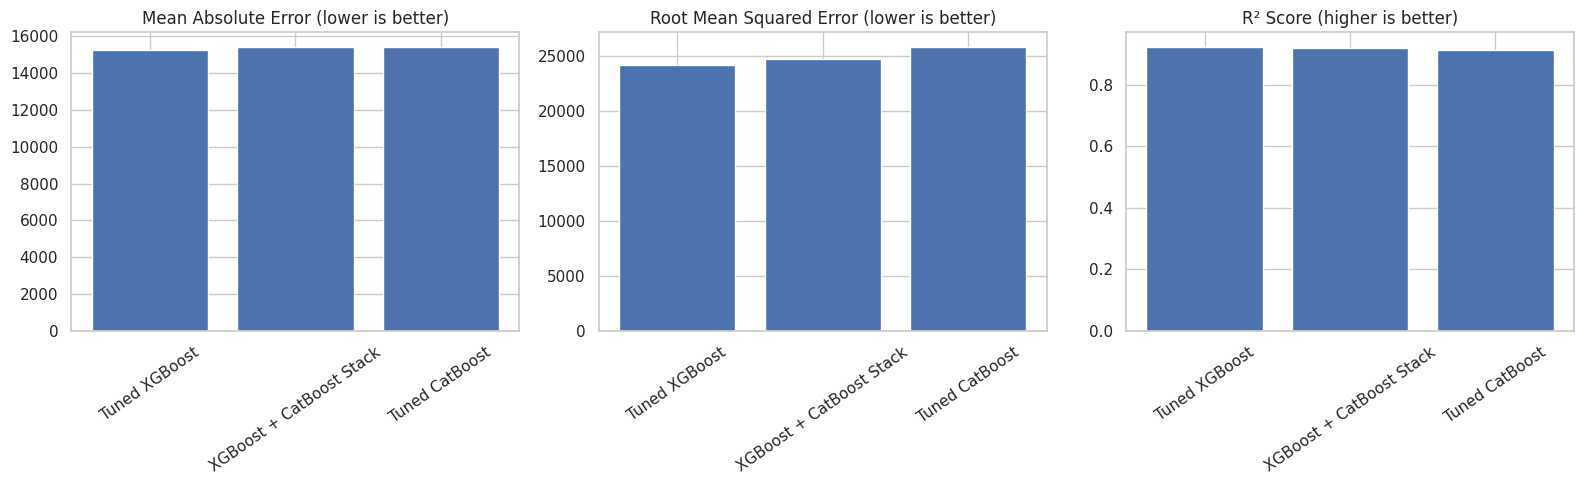

Best model by validation RMSE: Tuned XGBoost
Best validation RMSE: $24,216.42


In [30]:

import matplotlib.pyplot as plt

comparison = stack_comparison.sort_values("RMSE")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = [
    ("MAE", "Mean Absolute Error (lower is better)"),
    ("RMSE", "Root Mean Squared Error (lower is better)"),
    ("R2", "R² Score (higher is better)")
]

for ax, (metric, title) in zip(axes, metrics):
    ax.bar(comparison["Model"], comparison[metric])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

print("Best model by validation RMSE:",
      comparison.iloc[0]["Model"])
print("Best validation RMSE: ${:,.2f}".format(
    comparison.iloc[0]["RMSE"]
))


In [31]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Get predictions from the two tuned base models
xgb_tuned_predictions = tuned_pipelines["XGBoost"].predict(X_valid)
cat_tuned_predictions = tuned_pipelines["CatBoost"].predict(X_valid)

blend_results = []

# Weight means the proportion assigned to XGBoost.
# The remaining proportion is assigned to CatBoost.
for xgb_weight in np.arange(0.0, 1.01, 0.05):
    cat_weight = 1.0 - xgb_weight

    blended_predictions = (
        xgb_weight * xgb_tuned_predictions
        + cat_weight * cat_tuned_predictions
    )

    blend_results.append({
        "XGBoost_Weight": round(xgb_weight, 2),
        "CatBoost_Weight": round(cat_weight, 2),
        "MAE": mean_absolute_error(
            y_valid, blended_predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_valid, blended_predictions
        )),
        "R2": r2_score(y_valid, blended_predictions)
    })

blend_results_df = pd.DataFrame(blend_results).sort_values(
    "RMSE"
).reset_index(drop=True)

print("TOP 10 BLENDING CONFIGURATIONS")
display(blend_results_df.head(10).round(4))

best_blend = blend_results_df.iloc[0]

print("\nBest XGBoost weight:", best_blend["XGBoost_Weight"])
print("Best CatBoost weight:", best_blend["CatBoost_Weight"])
print("Best blend RMSE: ${:,.2f}".format(best_blend["RMSE"]))

print("\nTuned XGBoost RMSE: ${:,.2f}".format(
    np.sqrt(mean_squared_error(
        y_valid, xgb_tuned_predictions
    ))
))


TOP 10 BLENDING CONFIGURATIONS


,XGBoost_Weight,CatBoost_Weight,MAE,RMSE,R2
0,1.00,0.00,15244.3343,24216.4196,0.9235
1,0.95,0.05,15218.4180,24237.7709,0.9234
2,0.90,0.10,15194.6761,24265.8434,0.9232
3,0.85,0.15,15174.5058,24300.6139,0.9230
4,0.80,0.20,15154.5966,24342.0536,0.9227
5,0.75,0.25,15138.6553,24390.1285,0.9224
6,0.70,0.30,15133.2667,24444.7994,0.9221
7,0.65,0.35,15133.1515,24506.0223,0.9217
8,0.60,0.40,15134.3910,24573.7482,0.9213
9,0.55,0.45,15135.6306,24647.9234,0.9208



Best XGBoost weight: 1.0
Best CatBoost weight: 0.0
Best blend RMSE: $24,216.42

Tuned XGBoost RMSE: $24,216.42


In [32]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluate the selected tuned XGBoost model
final_candidate = tuned_pipelines["XGBoost"]

final_valid_predictions = final_candidate.predict(X_valid)

final_mae = mean_absolute_error(y_valid, final_valid_predictions)
final_rmse = np.sqrt(mean_squared_error(y_valid, final_valid_predictions))
final_r2 = r2_score(y_valid, final_valid_predictions)

print("=" * 55)
print("FINAL MODEL SELECTION")
print("=" * 55)
print("Selected Model : Tuned XGBoost")
print(f"Validation MAE : ${final_mae:,.2f}")
print(f"Validation RMSE: ${final_rmse:,.2f}")
print(f"Validation R²  : {final_r2:.4f}")
print("=" * 55)

print("\nModel decision:")
print("Tuned XGBoost selected based on the lowest validation RMSE.")


FINAL MODEL SELECTION
Selected Model : Tuned XGBoost
Validation MAE : $15,244.33
Validation RMSE: $24,216.42
Validation R²  : 0.9235

Model decision:
Tuned XGBoost selected based on the lowest validation RMSE.


In [33]:

import time
import numpy as np
from sklearn.base import clone

# Create a fresh copy of the selected tuned model
final_model = clone(tuned_pipelines["XGBoost"])

print("Training final XGBoost model on the full dataset...")
start_time = time.time()

final_model.fit(X, y)

training_time = time.time() - start_time

print("\n" + "=" * 55)
print("FINAL MODEL TRAINING COMPLETED")
print("=" * 55)
print(f"Training records : {len(X)}")
print(f"Input features   : {X.shape[1]}")
print(f"Training time    : {training_time:.2f} seconds")
print("Model            : Tuned XGBoost")
print("=" * 55)


Training final XGBoost model on the full dataset...

FINAL MODEL TRAINING COMPLETED
Training records : 1460
Input features   : 79
Training time    : 3.42 seconds
Model            : Tuned XGBoost


In [34]:

import numpy as np
import pandas as pd

# Predict house prices for the unseen test dataset
test_predictions = final_model.predict(X_test)

# Create the Kaggle submission DataFrame
submission_df = pd.DataFrame({
    "Id": test_ids,
    "SalePrice": test_predictions
})

print("TEST PREDICTIONS GENERATED")
print("=" * 50)
print("Number of predictions:", len(test_predictions))
print("Expected test records:", len(test_df))
print("Missing predictions:", np.isnan(test_predictions).sum())
print("\nPrediction statistics:")
print(f"Minimum predicted price: ${test_predictions.min():,.2f}")
print(f"Maximum predicted price: ${test_predictions.max():,.2f}")
print(f"Mean predicted price   : ${test_predictions.mean():,.2f}")
print(f"Median predicted price : ${np.median(test_predictions):,.2f}")

print("\nSubmission preview:")
display(submission_df.head(10))

print("\nSubmission shape:", submission_df.shape)
print("Column names:", submission_df.columns.tolist())


TEST PREDICTIONS GENERATED
Number of predictions: 1459
Expected test records: 1459
Missing predictions: 0

Prediction statistics:
Minimum predicted price: $38,577.72
Maximum predicted price: $536,293.00
Mean predicted price   : $178,823.00
Median predicted price : $157,510.05

Submission preview:


,Id,SalePrice
0,1461,126189.953125
1,1462,158769.546875
2,1463,186487.390625
3,1464,190375.234375
4,1465,182737.031250
5,1466,175142.031250
6,1467,170513.468750
7,1468,167247.484375
8,1469,185835.062500
9,1470,128656.656250



Submission shape: (1459, 2)
Column names: ['Id', 'SalePrice']


In [35]:

import numpy as np
import pandas as pd
from pathlib import Path

# Validate the submission before saving
assert submission_df.shape == (1459, 2), "Unexpected submission shape!"
assert submission_df.columns.tolist() == ["Id", "SalePrice"], "Incorrect columns!"
assert submission_df["Id"].is_unique, "Duplicate house IDs detected!"
assert submission_df["SalePrice"].notna().all(), "Missing predictions detected!"
assert np.isfinite(submission_df["SalePrice"]).all(), "Invalid predictions detected!"
assert (submission_df["SalePrice"] > 0).all(), "Non-positive prices detected!"

# Save the file
submission_path = Path("submission.csv")
submission_df.to_csv(submission_path, index=False)

# Read it back to verify the saved file
verified_submission = pd.read_csv(submission_path)

print("=" * 55)
print("KAGGLE SUBMISSION FILE CREATED SUCCESSFULLY")
print("=" * 55)
print("File name       :", submission_path.resolve())
print("File size       :", f"{submission_path.stat().st_size:,} bytes")
print("Rows            :", len(verified_submission))
print("Columns         :", verified_submission.columns.tolist())
print("Missing values  :", int(verified_submission.isna().sum().sum()))
print("Unique IDs      :", verified_submission["Id"].nunique())
print("Positive prices :", bool((verified_submission["SalePrice"] > 0).all()))
print("\nFirst 5 rows:")
display(verified_submission.head())


KAGGLE SUBMISSION FILE CREATED SUCCESSFULLY
File name       : /content/submission.csv
File size       : 21,639 bytes
Rows            : 1459
Columns         : ['Id', 'SalePrice']
Missing values  : 0
Unique IDs      : 1459
Positive prices : True

First 5 rows:


,Id,SalePrice
0,1461,126189.95
1,1462,158769.55
2,1463,186487.39
3,1464,190375.23
4,1465,182737.03


In [36]:

from google.colab import files

files.download("submission.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>